In [57]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 1. Regla del Trapecio.

Vamos a leer los datos y a gráficar los datos para ver como se comportan 

In [58]:
# Vamos a leer los archivos usando un programa que ya teniamos de la tarea 3 

entrada = open("data/velocidades.txt", "r")    # esto es un buffer
datos = [[], []]
for linea in entrada:
    #print(linea)
    palabras = linea.split()
    palabras = list(map(float, palabras))
    for j in range(len(palabras)):
        datos[j].append(palabras[j])

    #print(palabras)
datos = np.array(datos)

la cantidad de datos de tiempo es 101


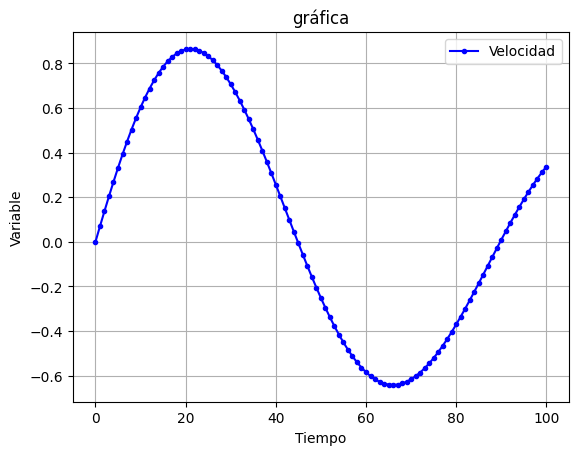

In [59]:
tiempo, velocidad = datos[0], datos[1]
print(f"la cantidad de datos de tiempo es {len(tiempo)}")
plt.title("gráfica")
plt.xlabel("Tiempo")
plt.ylabel("Variable")
plt.plot(tiempo, velocidad, label = "Velocidad", marker = ".", c = "blue")
plt.grid()
plt.legend(loc = "best")


## Distancia recorrida
Vamos a calcular la distancia recorrida en la dirección $x$, para ello notemos lo siguiente:

$$
\begin{aligned}
\text{Distancia total}
&= \frac{1}{2}\Big[
(t_1-t_0)(f(t_1)+f(t_0))\\
&\quad +(t_2-t_1)(f(t_2)+f(t_1))\\
&\quad +(t_3-t_2)(f(t_3)+f(t_2))\\
&\quad +\cdots
+(t_{101}-t_{100})(f(t_{101})+f(t_{100}))
\Big]\\[10pt]
&= \frac{1}{2}
\left[
\sum_{i=0}^{n-1}
(t_{i+1}-t_i)
\left[f(t_i)+f(t_{i+1})\right]
\right]
\end{aligned}
$$

Si definimos:

$$
f(t_i)=|V_i|
$$

Entonces:

$$
\boxed{
\text{Distancia total}
=
\frac{1}{2}
\left[
\sum_{i=0}^{n-1}
(t_{i+1}-t_i)
(|V_i|+|V_{i+1}|)
\right]
}
$$
Para sacar la base correcta debemos considerar que la función es positiva

In [60]:
Distancia = 0 #Definimos nuestras variables

for i in range(0,len(tiempo)-1):
    Distancia += (tiempo[(i+1)]-tiempo[i]) * (np.abs(velocidad[(i+1)])+np.abs(velocidad[i]))
    #print(Distancia, tiempo[i+1], tiempo[i], velocidad[i])
distancia_total = Distancia/2
print(f"La distancia recorrida total es {distancia_total:.4} m")

La distancia recorrida total es 44.77 m


Para cada t, la distancia en el instante t se tiene lo siguiente

In [61]:
def distancia_recorrida(t):
    t = int(t)
    Distancia = 0 #Definimos nuestras variables
    if t>= 0 and t <= 100:
        for i in range(0,t):
            Distancia += (tiempo[(i+1)]-tiempo[i]) * (np.abs(velocidad[(i+1)])+np.abs(velocidad[i]))
            #print(Distancia, tiempo[i+1], tiempo[i], velocidad[i])
        
        return Distancia/2
    if t>100 or t<0:
        print("Tu número debe de estar entre 0 y 100")
        return None
    

In [62]:
distancia= []
for i in range(0,101):
    print(f"la distancia recorrida en el instante t = {i} es {distancia_recorrida(i)}")
    distancia.append(distancia_recorrida(i))

la distancia recorrida en el instante t = 0 es 0.0
la distancia recorrida en el instante t = 1 es 0.034739
la distancia recorrida en el instante t = 2 es 0.138325
la distancia recorrida en el instante t = 3 es 0.309338
la distancia recorrida en el instante t = 4 es 0.5460455
la distancia recorrida en el instante t = 5 es 0.8464149999999999
la distancia recorrida en el instante t = 6 es 1.2081285
la distancia recorrida en el instante t = 7 es 1.6285975
la distancia recorrida en el instante t = 8 es 2.10498
la distancia recorrida en el instante t = 9 es 2.6341965
la distancia recorrida en el instante t = 10 es 3.212949
la distancia recorrida en el instante t = 11 es 3.83774
la distancia recorrida en el instante t = 12 es 4.504892
la distancia recorrida en el instante t = 13 es 5.2105685
la distancia recorrida en el instante t = 14 es 5.9507945
la distancia recorrida en el instante t = 15 es 6.721477999999999
la distancia recorrida en el instante t = 16 es 7.518431999999999
la distancia r

la cantidad de datos de tiempo es 101


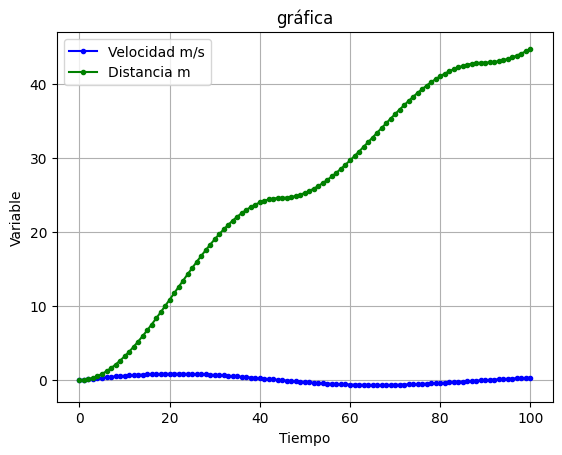

In [63]:
print(f"la cantidad de datos de tiempo es {len(tiempo)}")
plt.title("gráfica")
plt.xlabel("Tiempo")
plt.ylabel("Variable")
plt.plot(velocidad, label = "Velocidad m/s", marker = ".", c = "blue")
plt.plot( distancia, label = "Distancia m", marker = ".", c = "green")
plt.grid()
plt.legend(loc = "best")

# Ejercicio 2 

In [64]:
# Primero tenemos que la integral de Simpson está dada por: 
# Dada una función, tenemos un N = lo que quiera, y los límites de integración son a y b 

def IntegralSimsom(f, N, b,a):
    if N<= 0 or N % 2 != 0: 
        raise ValueError("N debe ser positivo y par")
    else:
        h = (b-a)/N
        suma_par = 0 
        suma_impar = 0 
        for i in range(1,int((N/2))):
            suma_par += f(a+(2*i*h))
        for i in range(1,int((N/2))+1):
            suma_impar += f(a+(2*i-1)*h)
        return (h/3)* ((f(a)+f(b))  + (4 * suma_impar) + (2 * suma_par))

In [65]:
# Vamos a definir la función que va a dentro de la integral 
def cos_1(x,m, theta):
    return np.cos((m*theta)-(x*np.sin(theta)))

In [66]:
def J_Bessel(m, x):
    def f(theta):
        return cos_1(theta, m, x)

    return (1/np.pi)*IntegralSimsom(f, 1000, 0, np.pi)

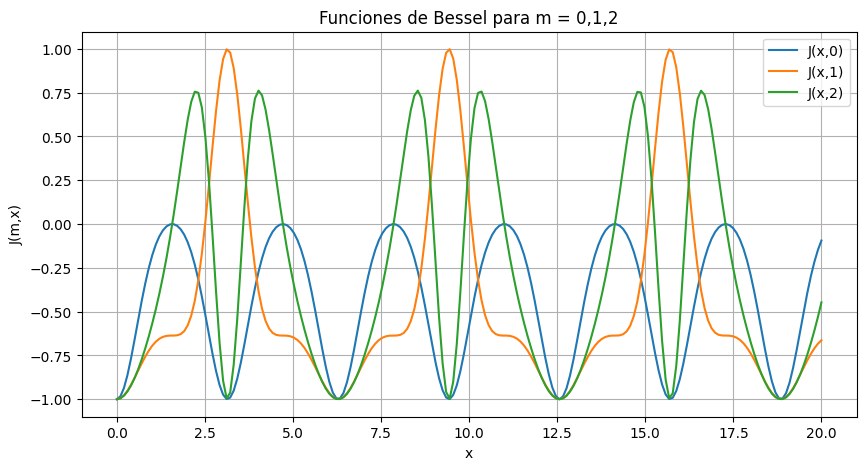

In [67]:
x_value = np.linspace(0,20, 200)
plt.figure(figsize=(10,5))
for i in range(3):
    plt.plot(x_value, J_Bessel(i, x_value), label = f"J(x,{i})")

plt.legend(loc = "best")
plt.title("Funciones de Bessel para m = 0,1,2")
plt.xlabel("x")
plt.ylabel("J(m,x)")
plt.grid()